## Exercise 9 - K-nearest neighbors

- Use the same dataset as in previous exercise (voice.csv)
- Dataset includes male and female voice samples with different features
- In this exercise you will use supervised machine learning method called K-nearest neighbors for the dataset
- **The goal of this exercise is to distinguish male and female voices from the given data**

1 Import all necessary libraries. Then load the dataset and save it to the dataframe.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn import neighbors
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns

data = pd.read_csv("data_files/voice.csv", delimiter=",")
voice_data = pd.DataFrame(data)

2 Filter the data so that only the following columns will be selected: **meanfun** and **IQR**. Then split the dataset so that 75 % of the data will be used for training.

In [28]:
X = voice_data[["meanfun", "IQR"]]
y = voice_data["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75, random_state=42)

3 Find the optimal value for k comparing possible values and error rate.

In [29]:
error_rates = []
k_values = range(1, 21)

for k in k_values:
    knn_temp = neighbors.KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    predictions_temp = knn_temp.predict(X_test)

    error_rates.append(np.mean(predictions_temp != y_test))

optimal_k = k_values[np.argmin(error_rates)]
print(f"Optimaalinen k-arvo: {optimal_k}")

Optimaalinen k-arvo: 13


4 Define a function and include the following operations inside the function:
   - Define a classifier
   - Fit the data for the classifier
   - Calculate minimum and maximum values for boundaries for meanfun and IQR
   - Run predictions
   - Draw a chart from predicted data utilising previously defined colormaps and add trained datapoints to the chart

Utilise your function and call it using the optimal k value chosen previously.

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


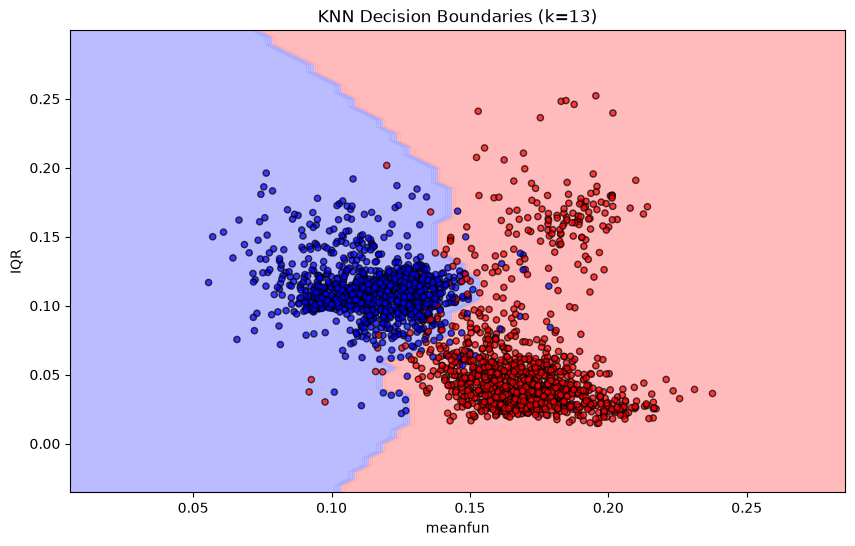

In [30]:
def plot_knn_decision_boundaries(k_val, X_tr, y_tr, X_te, y_te):
    # Define classifier and fit data
    clf = neighbors.KNeighborsClassifier(n_neighbors=k_val)
    clf.fit(X_tr, y_tr)
    
    # Calculate min and max values for boundaries for meanfun and IQR
    x_min, x_max = X_tr.iloc[:, 0].min() - 0.05, X_tr.iloc[:, 0].max() + 0.05
    y_min, y_max = X_tr.iloc[:, 1].min() - 0.05, X_tr.iloc[:, 1].max() + 0.05
    
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.005),
                         np.arange(y_min, y_max, 0.005))
    
    # Run predictions on grid
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    labels_mapping = {label: idx for idx, label in enumerate(np.unique(y_tr))}
    Z_numeric = np.array([labels_mapping[label] for label in Z])
    Z_numeric = Z_numeric.reshape(xx.shape)
    
    # Draw chart with colormaps and trained datapoints
    plt.figure(figsize=(10, 6))
    cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
    cmap_bold = ListedColormap(['#FF0000', '#0000FF'])
    
    plt.contourf(xx, yy, Z_numeric, cmap=cmap_light, alpha=0.8)
    
    # Add trained datapoints
    y_tr_numeric = np.array([labels_mapping[label] for label in y_tr])
    plt.scatter(X_tr.iloc[:, 0], X_tr.iloc[:, 1], c=y_tr_numeric, cmap=cmap_bold, edgecolor='k', s=20, alpha=0.7)
    
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(f"KNN Decision Boundaries (k={k_val})")
    plt.xlabel("meanfun")
    plt.ylabel("IQR")
    plt.show()
    
    # Return predictions for validation
    return clf.predict(X_te)

# Utilise the function using the optimal k value
y_pred = plot_knn_decision_boundaries(optimal_k, X_train, y_train, X_test, y_test)

5 Validate KNN prediction results using confusion matrix.

Confusion Matrix:
[[360   7]
 [ 11 414]]


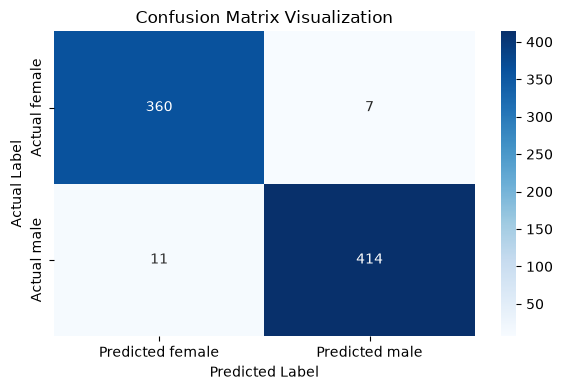

In [31]:
labels_order = np.unique(y_test)
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=[f"Predicted {l}" for l in labels_order], 
    yticklabels=[f"Actual {l}" for l in labels_order]
)
plt.title("Confusion Matrix Visualization")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()